# Regression và ranking metrics

Với bài toán dự đoán một con số (regression), như đoán số người đến buổi học, sai số đo bằng khoảng cách: đoán 32 khi thực tế là 30 thì sai 2. Với bài toán xếp hạng (ranking), như gợi ý ba bài luyện phù hợp nhất cho mỗi học sinh, điều quan trọng là bài phù hợp có nằm gần đầu danh sách không. Bài này học các metric cho hai loại bài toán đó: MAE, MSE, RMSE, $R^2$, MAPE và MAP@k, và phân biệt metric dùng để chấm với loss dùng để huấn luyện.

> **Mục tiêu**
>
> - Tính MAE, MSE, RMSE và $R^2$.
> - Biết khi nào MAPE không dùng được.
> - Tính AP@k và MAP@k.
> - Phân biệt loss dùng để huấn luyện với metric dùng để chấm.

## Độ lớn lỗi và đơn vị

Gọi phần dư $r_i=\hat y_i-y_i$. Với $n$ mẫu,

$$\operatorname{MAE}=\frac1n\sum_i|r_i|,\qquad
\operatorname{MSE}=\frac1n\sum_i r_i^2,\qquad
\operatorname{RMSE}=\sqrt{\operatorname{MSE}}.$$

MAE giữ cùng đơn vị với target. Nếu target là số người, MAE cũng là số người. MSE có đơn vị người bình phương, nên khó đọc trực tiếp; RMSE đưa về người. Cả ba đều càng thấp càng tốt. RMSE 0.5 tỉ đồng cho giá nhà nghĩa là dự đoán thường lệch cỡ nửa tỉ, với lỗi lớn được tính nặng hơn.



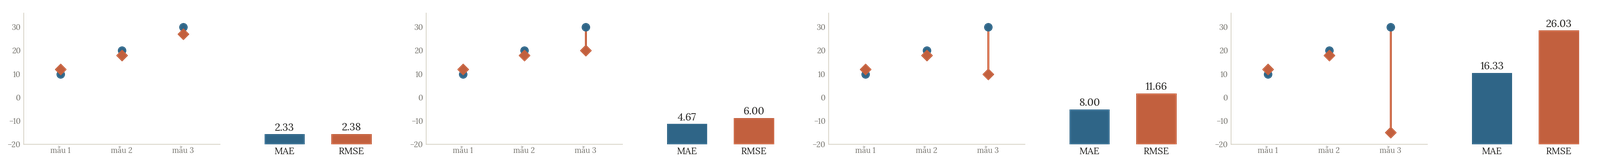

Bình phương khiến lỗi 4 đóng góp 16, gấp 16 lần lỗi 1; trong MAE chỉ gấp bốn lần. MSE/RMSE nhạy với sai số lớn và outlier. Điều ấy có thể phù hợp nếu lỗi rất lớn đắt giá; cũng có thể bị một nhãn nhập nhầm chi phối. Không coi outlier mặc nhiên là rác: cần kiểm ý nghĩa và nguồn ghi nhãn.

RMSE **không** phải trung bình căn của từng lỗi bình phương. Làm theo cách ấy sẽ thành MAE, vì $\sqrt{r_i^2}=|r_i|$. Thứ tự lấy trung bình và căn quan trọng.

Huber loss nằm giữa hai cách: bằng $\tfrac12 e^2$ khi $|e|\le\delta$ và bằng $\delta(|e|-\tfrac12\delta)$ khi xa hơn. Gần 0 nó trơn như MSE, ở xa tăng tuyến tính như MAE, nên một điểm ngoại lai không kéo lệch cả mô hình: với $\delta=1$, lỗi $e=3$ chỉ góp 2.5 thay vì 4.5.

**Hỏi nhanh.** Đổi target từ giờ sang phút, nên mọi target và mọi dự đoán đều nhân 60. MSE thay đổi thế nào?

- A. Không đổi, vì target và dự đoán cùng nhân 60
- B. Nhân 60, giống phần dư
- C. Nhân $\sqrt{60}$
- D. Nhân $60^2 = 3600$

<details><summary>Đáp án</summary>

D. Nhân $60^2 = 3600$

Phần dư nhân 60, nên bình phương của nó nhân 3600. MAE và RMSE thì chỉ nhân 60. Tỉ số giữa hai mô hình không đổi, nên phép so sánh vẫn công bằng; chỉ con số tuyệt đối đổi theo đơn vị.

</details>

## R²: so với mốc đoán trung bình

Ba buổi có target $(10,20,30)$ và dự đoán $(12,18,27)$. Phần dư là $(2,-2,-3)$, nên MAE $=7/3\approx2.333$, MSE $=17/3\approx5.667$, RMSE $=\sqrt{17/3}\approx2.380$.

$R^2$ so tổng bình phương lỗi với phương án dự đoán trung bình của **tập đang chấm**:

$$R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}.$$

Trong ví dụ $\bar y=20$, mẫu số là $100+0+100=200$, nên $R^2=1-17/200=0.915$. Mốc “đoán trung bình tập chấm” chỉ dùng để định nghĩa metric: một model thật không được biết trung bình ấy. Baseline thật học trung bình train, nên trên validation nó thường có $R^2$ hơi dưới 0 chứ không đúng bằng 0.



In [ ]:
import numpy as np
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    mean_absolute_percentage_error,
)

y = np.array([10.0, 20.0, 30.0])
prediction = np.array([12.0, 18.0, 27.0])
residual = prediction - y
print('Phần dư:', residual)
print(f'MAE={mean_absolute_error(y, prediction):.3f}')
print(f'MSE={mean_squared_error(y, prediction):.3f}')
print(f'RMSE={np.sqrt(mean_squared_error(y, prediction)):.3f}')
print(f'R2={r2_score(y, prediction):.3f}')

Phần dư: [ 2. -2. -3.]
MAE=2.333
MSE=5.667
RMSE=2.380
R2=0.915


Các dòng phải khớp phép tính tay. $R^2=1$ là dự đoán đúng hết; bằng 0 là ngang mốc trung bình tập chấm; âm là tệ hơn mốc ấy. Nó không phải phần trăm số mẫu đoán đúng. Chẳng hạn $R^2=0.915$ không nói rằng 91.5% buổi có số người dự đoán chính xác.

Nếu mọi target của tập chấm bằng nhau, mẫu số bằng 0 và $R^2$ không xác định; scikit-learn khi đó trả về 0 hoặc 1 theo quy ước riêng. Ngoài ra, $R^2$ phụ thuộc độ phân tán của tập chấm, nên không so $R^2$ của hai bộ dữ liệu khác hẳn nhau để nói model nào tốt hơn.

**Hỏi nhanh.** Mô hình có $R^2 = -0.5$ trên validation. Con số này nói lên điều gì?

- A. Code chắc chắn sai dấu, vì $R^2$ là một bình phương
- B. Mô hình còn tệ hơn cách đoán hằng số bằng trung bình của tập chấm
- C. Mô hình đoán đúng chưa tới một nửa số mẫu validation
- D. Mô hình tốt hơn mức trung bình 50%, theo chiều ngược lại

<details><summary>Đáp án</summary>

B. Mô hình còn tệ hơn cách đoán hằng số bằng trung bình của tập chấm

$R^2 = -0.5$ nghĩa là tổng bình phương lỗi bằng 1.5 lần tổng bình phương độ lệch quanh trung bình. Cái tên “R bình phương” dễ gây hiểu nhầm: công thức là 1 trừ đi một tỉ số, nên âm là chuyện bình thường. $R^2$ cũng không đếm số mẫu đoán đúng.

</details>

## MAPE: tỉ lệ lỗi nhưng có mẫu số nguy hiểm

Mean absolute percentage error dùng độ lớn tương đối so với target:

$$\operatorname{MAPE}=\frac1n\sum_i\frac{|y_i-\hat y_i|}{|y_i|},\qquad y_i\ne0.$$

Muốn biểu diễn phần trăm, nhân kết quả với 100. Mẫu số là giá trị thật, không phải dự đoán: đoán 453 khi thật là 488 lệch $35/488\approx7.2\%$. Với ba buổi trên, các lỗi tương đối là 0.2, 0.1, 0.1: trung bình khoảng 0.1333, tức 13.33%.

Target nhỏ khiến cùng một lỗi tuyệt đối bị phạt lớn hơn. Đoán 2 khi thật là 1 sai 100%; đoán 101 khi thật là 100 chỉ sai 1%, dù cả hai sai một đơn vị. Nếu có $y=0$, công thức này chia 0. Thư viện thay mẫu số bằng một số rất nhỏ nên có thể trả số hữu hạn khổng lồ; đó không có nghĩa metric đã trở nên dễ diễn giải.

In [ ]:
print(f'MAPE dạng tỉ lệ={mean_absolute_percentage_error(y, prediction):.4f}')
print(f'MAPE phần trăm={100 * mean_absolute_percentage_error(y, prediction):.2f}%')
zero_case = mean_absolute_percentage_error([0.0, 10.0], [1.0, 9.0])
print(f'MAPE với target 0 theo thư viện={zero_case:.3e}')

MAPE dạng tỉ lệ=0.1333
MAPE phần trăm=13.33%
MAPE với target 0 theo thư viện=2.252e+15


Dòng cuối cho thấy: có target bằng 0 thì MAPE của thư viện ra một số khổng lồ, chẳng còn ý nghĩa. Vì vậy trước khi dùng MAPE, kiểm xem target có số 0 không. Nếu đề có cách xử lý riêng, như cộng thêm một số nhỏ vào mẫu số hay dùng sMAPE, thì cài đúng như đề.



Để thấy việc chọn metric làm đổi quyết định, xét hai dự đoán sau trên cùng target $(1,100)$.

In [ ]:
small_large = np.array([1.0, 100.0])
candidate_a = np.array([2.0, 100.0])
candidate_b = np.array([1.0, 104.0])
for name, pred in [('A', candidate_a), ('B', candidate_b)]:
    mae = mean_absolute_error(small_large, pred)
    mape = mean_absolute_percentage_error(small_large, pred)
    print(f'{name}: MAE={mae:.3f}, MAPE={mape:.3f}')

A: MAE=0.500, MAPE=0.500
B: MAE=2.000, MAPE=0.020


Theo MAE, A tốt hơn vì tổng lỗi chỉ là 1 thay vì 4. Theo MAPE, B tốt hơn vì tránh lỗi trên target 1. Không có mâu thuẫn: hai metric đặt trọng số khác nhau cho hai buổi.

**Hỏi nhanh.** Trong dữ liệu có những target bằng 0, mà đề chấm bằng MAPE. Ta xử lý thế nào?

- A. Bỏ các hàng có target 0 khỏi validation cho số đẹp hơn
- B. Cộng 1 vào mọi target, vẫn gọi là MAPE như đề
- C. Dùng hàm MAPE của thư viện, vì nó đã tự xử lý chia cho 0
- D. Đọc công thức chấm của đề rồi cài đúng như thế

<details><summary>Đáp án</summary>

D. Đọc công thức chấm của đề rồi cài đúng như thế

Điểm trên validation phải được tính giống hệt điểm thật của đề. Bỏ hàng hay cộng 1 đều làm con số ở máy mình lệch đi. Hàm của thư viện chỉ thay mẫu số 0 bằng một số rất nhỏ, nên ra con số khổng lồ như $2.252\times 10^{15}$ ở trên. Nếu đề có quy ước riêng cho trường hợp này, ta cài đúng quy ước ấy. Nếu được tự chọn metric, nên cân nhắc thước đo không chia cho target.

</details>

## Loss học và metric chấm có thể khác nhau

**Loss** là hàm mà thuật toán làm nhỏ nhất khi học trên train. **Metric** là thước đo dùng để chấm trên validation và test, theo đúng yêu cầu của đề. Hai thứ có thể trùng nhau, nhưng không bắt buộc: một model học bằng MSE vẫn có thể được chấm bằng MAE.

Loss quyết định model đoán về đâu. Nếu chỉ được đoán một hằng số, MSE nhỏ nhất khi đoán bằng trung bình (mean), còn MAE nhỏ nhất khi đoán bằng trung vị (median). Train có target $(10, 10, 10, 50)$: mean bằng 20, bị mẫu 50 kéo lên; median vẫn là 10.

Loss còn phải có đạo hàm dùng được (bài 0.6). Accuracy thì không: nhích trọng số một chút thường không đổi nhãn nào, nên đạo hàm gần như luôn bằng 0. Vì vậy bộ phân loại học bằng cross-entropy (bài 2.3) rồi mới chấm bằng accuracy.



In [ ]:
train_targets = np.array([10.0, 10.0, 10.0, 50.0])
for name, value in [('mean', train_targets.mean()), ('median', np.median(train_targets))]:
    constant_prediction = np.full(len(train_targets), value)
    print(
        f'{name}: giá trị={value:.1f}, '
        f'MAE={mean_absolute_error(train_targets, constant_prediction):.1f}, '
        f'MSE={mean_squared_error(train_targets, constant_prediction):.1f}'
    )

mean: giá trị=20.0, MAE=15.0, MSE=300.0
median: giá trị=10.0, MAE=10.0, MSE=400.0


Mean có MSE thấp hơn, median có MAE thấp hơn: mỗi loss kéo dự đoán về “tâm” riêng của nó. Muốn chọn model thì vẫn đo trên validation bằng metric của đề. Riêng MSE và RMSE luôn xếp hạng các model giống nhau, vì RMSE chỉ là căn bậc hai của MSE.

**Hỏi nhanh.** Muốn phạt lỗi lớn còn mạnh hơn MSE, một bạn đề xuất học linear regression bằng trung bình lập phương của phần dư, $\frac1n\sum_i(\hat y_i - y_i)^3$. Cách này sai ở đâu?

- A. Lỗi lớn bị phạt quá mạnh, nên mô hình chỉ chạy theo vài điểm ngoại lai
- B. Tính lập phương quá chậm khi dữ liệu lớn
- C. Phần dư âm cho lập phương âm, nên càng đoán thấp thì loss càng giảm mãi
- D. Đơn vị bị lập phương nên không đọc được lỗi lớn hay nhỏ

<details><summary>Đáp án</summary>

C. Phần dư âm cho lập phương âm, nên càng đoán thấp thì loss càng giảm mãi

Khi $r < 0$ thì $r^3 < 0$. Kéo mọi dự đoán xuống thật thấp là loss giảm không có điểm dừng, nên bài toán không có nghiệm. Đơn vị lạ chỉ là chuyện phụ. Muốn phạt lỗi lớn mạnh hơn thì phải giữ dấu dương, chẳng hạn dùng $|r|^3$, và vẫn chọn mô hình theo metric của đề.
Phỏng theo: [CMU 10-601 · Exam 1 Practice · Q5.4](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam1_practice_problems.pdf#page=20)

</details>

## Ranking: một danh sách, không phải một số

Câu lạc bộ muốn gợi ý ba bài luyện cho mỗi học sinh. Với một query, tức một yêu cầu gợi ý của một học sinh, ta có tập bài thật sự phù hợp (relevant). Một danh sách tốt đặt nhiều bài phù hợp gần đầu. Xét tập relevant `{A,C,E}` và danh sách `[A,B,C]`: vị trí 1 đúng, vị trí 2 sai, vị trí 3 đúng.

Precision@r là số bài relevant trong $r$ vị trí đầu chia $r$. Average precision ở top $k$ cần một quy ước mẫu số. Trong bài này chọn

$$\operatorname{AP@}k=\frac{\sum_{r=1}^{k} P@r\cdot\operatorname{rel}(r)}{\min(R,k)},\qquad R>0,$$

Ở đây $R$ là số bài thật sự phù hợp, $\operatorname{rel}(r)$ bằng 1 nếu bài ở vị trí $r$ phù hợp, bằng 0 nếu không. Nói cách khác: tại mỗi vị trí có bài đúng, lấy precision tính đến vị trí đó, cộng lại, rồi chia cho số bài đúng tối đa có thể có trong top $k$.

Mỗi đề có thể định nghĩa AP hơi khác: có đề chia cho $R$ thay vì $\min(R, k)$, có đề bỏ query không có bài phù hợp nào, có đề quy định riêng khi một bài bị lặp. Vì vậy đọc kỹ công thức của đề trước khi viết hàm chấm. Code trong bài cho AP bằng 0 khi $R = 0$, và không cho phép bài lặp trong top $k$.



Với `[A,B,C]`, tử số là $1+2/3=5/3$, mẫu số là 3, nên AP@3 $=5/9$. Với `[C,E,B]`, tử số là $1+1=2$, mẫu số 3, nên AP@3 $=2/3$. Precision@3 của cả hai bằng $2/3$, nhưng AP thích cách đặt bài đúng sớm hơn.

Tìm kiếm và hệ gợi ý (recommender) đều là bài xếp hạng: quan trọng là thứ tự, không phải con số chính xác. Ngoài AP còn hai metric xếp hạng hay gặp:

- **MRR**: trung bình của $1/\text{hạng}$ của đáp án đúng đầu tiên. Ba câu hỏi có đáp án đúng ở hạng 1, hạng 3 và không có, cho MRR $= (1 + 1/3 + 0)/3 \approx 0.44$.
- **nDCG**: dùng khi độ phù hợp có nhiều mức. $\mathrm{DCG} = \sum_r \mathrm{rel}_r / \log_2(r + 1)$ cộng điểm phù hợp, giảm dần theo vị trí; nDCG chia DCG cho DCG của thứ tự lý tưởng để ra một số trong $[0, 1]$.

**Hỏi nhanh.** Các bài liên quan (relevant) là `{A,C,E}`. So hai danh sách xếp hạng `[B,A,C]` và `[A,B,C]` ở top 3. Precision@3 và AP@3 của hai danh sách khác nhau thế nào?

- A. Precision@3 bằng nhau, AP@3 cũng bằng nhau
- B. Precision@3 bằng nhau, nhưng AP@3 của `[B,A,C]` thấp hơn
- C. Precision@3 của `[B,A,C]` thấp hơn, còn AP@3 bằng nhau
- D. Cả precision@3 lẫn AP@3 của `[B,A,C]` đều thấp hơn

<details><summary>Đáp án</summary>

B. Precision@3 bằng nhau, nhưng AP@3 của `[B,A,C]` thấp hơn

Cả hai danh sách có hai bài relevant trong top 3, nên $P@3 = 2/3$. AP@3 của `[A,B,C]` là $(1 + 2/3)/3 = 5/9 \approx 0.556$. AP@3 của `[B,A,C]` là $(1/2 + 2/3)/3 = 7/18 \approx 0.389$. Lùi bài đúng đầu tiên xuống một hạng làm AP giảm, dù precision@3 vẫn thế.

</details>

## Cài một scorer nhỏ và kiểm tay

**MAP@k** (mean average precision) là trung bình AP@k của mọi query, mỗi query nặng như nhau. Đừng nối mọi danh sách lại rồi tính AP một lần: mỗi học sinh có tập bài phù hợp riêng.

In [ ]:
def ap_at_k(ranking, relevant, k):
    assert k >= 1, 'k phải dương'
    top = list(ranking[:k])
    assert len(top) == len(set(top)), 'Không cho duplicate trong top k'
    relevant = set(relevant)
    if not relevant:
        return 0.0
    hits = 0
    total = 0.0
    for rank, item in enumerate(top, start=1):
        if item in relevant:
            hits += 1
            total += hits / rank
    return total / min(len(relevant), k)

rankings = [['A', 'B', 'C'], ['B', 'D', 'E']]
relevant_sets = [{'A', 'C', 'E'}, {'D'}]
ap_scores = [ap_at_k(rank, rel, 3) for rank, rel in zip(rankings, relevant_sets)]
print('AP@3 từng query:', np.round(ap_scores, 6))
print(f'MAP@3={np.mean(ap_scores):.6f}')
assert np.isclose(ap_scores[0], 5 / 9)
assert np.isclose(ap_scores[1], 1 / 2)

AP@3 từng query: [0.555556 0.5     ]
MAP@3=0.527778


Query thứ hai có một bài relevant ở hạng 2 nên AP@3 $=1/2$. MAP của hai query là $(5/9+1/2)/2=19/36\approx0.527778$. Các assert đối chiếu với phép tính độc lập, giống kiểm một hàm CP bằng vài trường hợp nhỏ có đáp án chắc chắn.

**Hỏi nhanh.** Bỏ dòng `assert` chặn mục trùng trong `ap_at_k`, rồi gọi `ap_at_k(['A', 'A', 'C'], {'A', 'C'}, 3)`. Kết quả là bao nhiêu?

- A. $1.0$, vì cả hai bài relevant đều có mặt
- B. $0.833$, vì lần xuất hiện thứ hai của A bị bỏ qua
- C. Báo lỗi, vì `relevant` là một set
- D. $1.5$, vì A được tính như hai bài đúng

<details><summary>Đáp án</summary>

D. $1.5$, vì A được tính như hai bài đúng

Cả ba vị trí đều được tính là đúng: $1/1 + 2/2 + 3/3 = 3$, chia cho $\min(2, 3) = 2$ ra $1.5$. AP lớn hơn 1 là dấu hiệu chắc chắn hàm chấm bị sai. Nếu hàm chấm không chặn mục trùng, một bài nộp lặp lại mục đúng sẽ được điểm cao vô lý, vì vậy đề thường quy định rõ cách xử lý mục trùng.

</details>

Chọn model gợi ý cũng cần chia dữ liệu như bài 1.3: theo người mới hoặc theo thời gian, và không đưa tương tác ở tương lai vào feature. Metric đúng mà cách chia sai thì điểm vẫn không đáng tin.

## Khi đi thi

- Viết hàm chấm theo đúng công thức của đề, kiểm bằng vài ví dụ tính tay có đáp án chắc chắn.
- Trước khi dùng MAPE, kiểm target có bằng 0 không; có outlier thì RMSE tăng mạnh hơn MAE.
- Ranking: tính AP từng query rồi mới lấy trung bình, và chặn mục trùng trong top $k$.

## Tóm tắt

- MAE giữ đơn vị; MSE phạt lỗi lớn; RMSE là căn của MSE.
- $R^2$ dùng mốc trung bình tập chấm và có thể âm.
- MAPE đặt trọng số lớn lên target nhỏ và cần quy ước khi target 0.
- AP@k thưởng bài relevant ở gần đầu; MAP trung bình theo query.
- Loss trên train và metric chọn/chấm phải được phân biệt rõ.

## Kiểm tra cuối bài

**Câu 1.** Trên năm buổi, lỗi tuyệt đối của mô hình A là $(1, 1, 1, 1, 8)$, của mô hình B là $(3, 3, 3, 3, 3)$. Theo MAE thì mô hình nào tốt hơn, theo RMSE thì sao?

- A. Theo MAE là A, theo RMSE là B
- B. Theo MAE là B, theo RMSE là A
- C. Theo cả hai đều là A
- D. Theo cả hai đều là B

<details><summary>Đáp án</summary>

A. Theo MAE là A, theo RMSE là B

MAE của A là $12/5 = 2.4$, của B là 3. RMSE của A là $\sqrt{68/5} \approx 3.69$, của B là 3. Một lỗi bằng 8 của A khi bình phương thành 64, đủ lật ngược kết quả. Muốn biết đề phạt lỗi lớn nặng đến đâu, ta đọc metric.

</details>

**Câu 2.** Mô hình đoán số người đến có MSE bằng 9, đơn vị là “người bình phương”. RMSE bằng bao nhiêu?

- A. 9 người
- B. 3 người
- C. 81 người
- D. 3 người bình phương

<details><summary>Đáp án</summary>

B. 3 người

RMSE là căn bậc hai của MSE: $\sqrt 9 = 3$. Lấy căn cũng đưa đơn vị về lại “người”, cùng đơn vị với target. Vì vậy khi báo cáo, RMSE dễ đọc hơn MSE.

</details>

**Câu 3.** Một đề tính điểm theo RMSE: $\text{điểm} = \dfrac{X_\text{baseline} - X}{X_\text{baseline} - X_\text{best}} \times 100\%$, và bằng 0 nếu $X$ tệ hơn baseline. Baseline có RMSE 2.0, bài tốt nhất có 1.0, đội mình có 1.4. Điểm hiện tại là bao nhiêu, và nếu RMSE giảm còn 1.2 thì được bao nhiêu?

- A. 40% và 20%
- B. 30% và 40%
- C. 71% và 83%
- D. 60% và 80%

<details><summary>Đáp án</summary>

D. 60% và 80%

$(2.0 - 1.4)/(2.0 - 1.0) = 60\%$ và $(2.0 - 1.2)/1.0 = 80\%$. Điểm đo xem ta đã đi được bao nhiêu phần đường từ baseline tới bài tốt nhất. Ở gần đỉnh, mỗi 0.1 RMSE đáng 10 điểm. Còn tệ hơn baseline thì được 0 điểm, dù mô hình vẫn chạy.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 2](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-2-problems.pdf#page=13)

</details>

**Câu 4.** Lỗi của mỗi mẫu được tính bằng $10^3 \cdot e_\text{vị trí} + 3 \cdot 10^{-3} \cdot e_\text{trường}$. Ở đây $e_\text{vị trí}$ là tổng sai số tuyệt đối của tọa độ nguồn, còn $e_\text{trường}$ là RMSE của 100 giá trị cường độ. Trên validation, trung bình $e_\text{vị trí} = 0.02$ và $e_\text{trường} = 50$. Ta chỉ đủ thời gian làm một việc. Việc nào giảm lỗi nhiều hơn?

- A. Giảm lỗi vị trí còn 0.01
- B. Giảm RMSE cường độ còn 25
- C. Hai việc như nhau, vì cùng giảm một nửa
- D. Không so được, vì hai lỗi khác đơn vị

<details><summary>Đáp án</summary>

A. Giảm lỗi vị trí còn 0.01

Lỗi hiện tại là $20 + 0.15 = 20.15$. Giảm lỗi vị trí còn 0.01 thì lỗi còn $10.15$. Giảm RMSE cường độ còn 25 thì lỗi chỉ còn $20.075$. Các hệ số trong công thức cho biết phần nào đang kéo điểm xuống, nên phải đọc công thức chấm trước khi chọn việc.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 1](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-1-problems.pdf#page=12)

</details>

**Câu 5.** Hai buổi có target là 2 và 50, mô hình đoán 3 và 60. Ta chỉ được sửa một dự đoán về đúng giá trị thật. Muốn MAPE giảm nhiều nhất thì sửa buổi nào? Muốn MAE giảm nhiều nhất thì sửa buổi nào?

- A. MAPE thì sửa buổi 50, MAE thì sửa buổi 2
- B. MAPE thì sửa buổi 2, MAE thì sửa buổi 50
- C. Cả hai đều sửa buổi 50, vì lỗi 10 lớn hơn
- D. Cả hai đều sửa buổi 2, vì lỗi tương đối lớn hơn

<details><summary>Đáp án</summary>

B. MAPE thì sửa buổi 2, MAE thì sửa buổi 50

MAPE hiện là $(0.5 + 0.2)/2 = 0.35$. Sửa buổi 2 thì còn $0.10$, sửa buổi 50 thì còn $0.25$. MAE hiện là $5.5$. Sửa buổi 2 thì còn $5$, sửa buổi 50 thì còn $0.5$. Cùng một dữ liệu, metric quyết định ta nên dồn công sức vào đâu.

</details>

**Câu 6.** Target train là $(0, 0, 0, 8, 12)$. Nếu chỉ được đoán một hằng số cho mọi mẫu, hằng số nào cho MAE nhỏ nhất, hằng số nào cho MSE nhỏ nhất?

- A. MAE nhỏ nhất với 0, MSE nhỏ nhất với 4
- B. Cả hai đều nhỏ nhất với 0
- C. Cả hai đều nhỏ nhất với 4
- D. MAE nhỏ nhất với 4, MSE nhỏ nhất với 0

<details><summary>Đáp án</summary>

A. MAE nhỏ nhất với 0, MSE nhỏ nhất với 4

Median, ở đây bằng 0, làm tổng sai số tuyệt đối nhỏ nhất. Mean bằng 4 làm tổng sai số bình phương nhỏ nhất, dù không target nào bằng 4.
Phỏng theo: [CMU 10-601 · Exam 1 Practice · Q5.5](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam1_practice_problems.pdf#page=20)

</details>

**Câu 7.** Các mục relevant là B, D, E, F. Hệ thống trả về thứ hạng [A, B, C, D]. AP@4 dùng mẫu số $\min(R, 4)$, với $R$ là tổng số mục relevant. AP@4 bằng bao nhiêu?

- A. 1/8
- B. 1
- C. 1/4
- D. 1/2

<details><summary>Đáp án</summary>

C. 1/4

Hai mục đúng nằm ở hạng 2 và hạng 4, và precision tại hai hạng ấy đều là 1/2. $R = 4$ nên mẫu số là $\min(4, 4) = 4$. Vậy $\text{AP@4} = (1/2 + 1/2)/4 = 1/4$. Còn 1/2 là precision@4, một đại lượng khác.

</details>

**Câu 8.** Hai query có AP là 0.8 và 0.2. Query đầu có 1 mục relevant, query sau có 9. MAP, tức trung bình đều theo query, bằng bao nhiêu?

- A. 0.50
- B. 0.80
- C. 1.00
- D. 0.26

<details><summary>Đáp án</summary>

A. 0.50

MAP lấy trung bình đều theo query: $(0.8 + 0.2)/2 = 0.50$. Còn 0.26 là trung bình có trọng số theo số mục relevant, $(0.8 \cdot 1 + 0.2 \cdot 9)/10$, khác với định nghĩa của đề.

</details>

**Câu 9.** Có $R = 5$ mục relevant. Hệ thống chỉ trả về $k = 3$ kết quả, và cả ba đều relevant. Nếu chia cho $R$ thì AP@3 bằng bao nhiêu? Nếu chia cho $\min(R, k)$ thì sao?

- A. 0.6 và 0.6
- B. 0.6 và 1.0
- C. 1.0 và 0.6
- D. 1.0 và 1.0

<details><summary>Đáp án</summary>

B. 0.6 và 1.0

Precision tại cả ba vị trí đều bằng 1, tổng là 3. Chia cho 5 ra 0.6, chia cho 3 ra 1. Hai quy ước cùng mang tên AP@k mà cho hai con số khác nhau, nên phải đọc đúng công thức của hàm chấm.

</details>

**Câu 10.** Trên cùng validation, mô hình A có MAE 2.0 và MSE 10. Mô hình B có MAE 2.4 và MSE 8. Cả hai đều học bằng MSE, nhưng đề chấm bằng MAE. Ta chọn mô hình nào?

- A. B, vì MSE trên validation thấp hơn
- B. Lấy trung bình MAE và MSE, chọn bên nhỏ hơn
- C. A, vì MAE trên validation thấp hơn
- D. B, vì MSE là loss dùng để học

<details><summary>Đáp án</summary>

C. A, vì MAE trên validation thấp hơn

Loss dùng để học và metric dùng để chọn có thể khác nhau. Đề chấm MAE thì ta chọn theo MAE: A có 2.0, thấp hơn 2.4 của B. MSE của B thấp hơn cũng không thay đổi được điều đó.

</details>

## Đọc thêm

- [scikit-learn — Regression metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics). Tra định nghĩa, đơn vị, multioutput và giới hạn của $R^2$.
- [scikit-learn — Mean absolute percentage error](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_absolute_percentage_error.html). Xem cách trả tỉ lệ và xử lý target gần 0.
- Manning, Raghavan, Schütze — [Introduction to Information Retrieval: Evaluation of ranked retrieval results](https://nlp.stanford.edu/IR-book/html/htmledition/evaluation-of-ranked-retrieval-results-1.html). Đọc AP/MAP trong truy hồi, rồi đối chiếu phần cắt top-k của scorer đề.